# Q3 et Q4 : prévoir le rendement de chaque parcelle et mesurer l'erreur

**Projet Datamining, Sujet 6 : Domaine des Trois Rivières** 

## Les deux questions

- **Q3.** Avant de répartir le budget intrants, on veut savoir ce que chaque parcelle va donner cette année.
- **Q4.** Sur quoi repose cette prévision, et de combien se trompe-t-elle ? Si l'erreur dépasse l'écart entre deux parcelles, elle ne sert à rien pour arbitrer.

## Démarche

1. Construire une base de travail propre (parcelles à série complète, sans conflit ni rendement nul).
2. Vérifier ce que représente le rendement du fichier parcelles, pour éviter qu'il ne contienne l'année à prédire.
3. Mesurer l'effet d'année (la météo touche toutes les parcelles à la fois).
4. Comparer des modèles avec un protocole qui respecte le temps : on n'utilise jamais une année pour prédire une année antérieure.
5. Retenir le modèle le plus simple parmi ceux qui font aussi bien, et l'appliquer pour la prévision de l'année à venir.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

pd.set_option("display.width", 120)
ANNEES_TEST = [2021, 2022, 2023, 2024]

parcelles = pd.read_csv("../data/processed/parcelles_clean.csv")
histo = pd.read_csv("../data/processed/historique_clean.csv")
print("Parcelles :", parcelles.shape, "| Historique :", histo.shape)

Parcelles : (220, 17) | Historique : (1338, 5)


## 2. Base de travail

L'historique contient 1 338 lignes pour 1 320 couples parcelle-millésime : les parcelles P44, P101 et P115 ont deux observations différentes pour chaque millésime, et rien ne permet de choisir laquelle est la bonne. Trois autres parcelles (P166, P184, P128) ont un rendement nul sur les six années, sans qu'on sache si c'est une absence de production réelle ou une erreur de saisie.

**Décision :** exclure ces 6 parcelles de la modélisation. Il reste 214 parcelles avec une série propre de 6 millésimes (2019 à 2024).

In [13]:
conflits = histo[histo.duplicated(["parcelle_id", "millesime"], keep=False)]["parcelle_id"].unique()
nuls = histo.loc[histo["rendement_nul_a_verifier"], "parcelle_id"].unique()
exclues = set(conflits) | set(nuls)

histo_ok = histo[~histo["parcelle_id"].isin(exclues)].copy()
parc_ok = parcelles[~parcelles["parcelle_id"].isin(exclues)].copy()

print("Parcelles exclues :", sorted(exclues))
print("Historique :", histo_ok.shape, "| Parcelles :", parc_ok.shape)
print("Doublons restants :", histo_ok.duplicated(["parcelle_id", "millesime"]).sum())

# Une ligne par parcelle, une colonne par millésime
piv = histo_ok.pivot(index="parcelle_id", columns="millesime", values="rendement_kg_ha")
print(piv.shape)

Parcelles exclues : ['P101', 'P115', 'P128', 'P166', 'P184', 'P44']
Historique : (1284, 5) | Parcelles : (214, 17)
Doublons restants : 0
(214, 6)


## 3. Que représente le rendement du fichier parcelles ?

Avant d'utiliser cette colonne, il faut savoir si elle contient l'année qu'on cherche à prédire. On la compare à chaque millésime et à des moyennes.

In [14]:
t = parc_ok.set_index("parcelle_id")["rendement_kg_ha"].loc[piv.index]

ecarts = {a: (t - piv[a]).abs().mean() for a in piv.columns}
ecarts["moyenne 2019-2024"] = (t - piv.mean(axis=1)).abs().mean()
ecarts["moyenne 2019-2023"] = (t - piv.loc[:, :2023].mean(axis=1)).abs().mean()
print("Écart absolu moyen avec le rendement du fichier parcelles :")
print(pd.Series(ecarts).round(0))

print("\nCorrélation avec chaque millésime :")
print(pd.concat([t, piv], axis=1).corr()["rendement_kg_ha"].round(2))

Écart absolu moyen avec le rendement du fichier parcelles :
2019                  494.0
2020                  631.0
2021                 1457.0
2022                  817.0
2023                  400.0
2024                  430.0
moyenne 2019-2024     171.0
moyenne 2019-2023     215.0
dtype: float64

Corrélation avec chaque millésime :
rendement_kg_ha    1.00
2019               0.90
2020               0.90
2021               0.88
2022               0.89
2023               0.90
2024               0.91
Name: rendement_kg_ha, dtype: float64


**Lecture.** Ce rendement ne correspond à aucune année précise (écarts de 400 à 1 457 kg/ha). Il est le plus proche de la moyenne des six millésimes (écart de 171) et corrélé à 0,88-0,91 avec chaque année : c'est un niveau propre à la parcelle. Comme il intègre en partie 2024, **on ne l'utilise pas comme variable d'entrée**, sinon l'erreur de test serait artificiellement basse. On calcule à la place nous-mêmes le niveau d'une parcelle à partir des années antérieures.

Cette corrélation de 0,9 entre millésimes est aussi un résultat pour la Q2 : une parcelle qui donne bien une année donne bien les autres.

## 4. L'effet d'année

La météo touche toutes les parcelles à la fois. Si le niveau moyen du domaine varie beaucoup d'une année à l'autre, une partie de l'erreur est impossible à prévoir à partir des caractéristiques d'une parcelle.

             mean     std
millesime                
2019       6285.0  1004.0
2020       7242.0  1190.0
2021       5246.0   877.0
2022       7495.0  1230.0
2023       6502.0  1040.0
2024       6944.0  1132.0
Écart-type entre parcelles (moyenne par parcelle) : 989
Écart-type entre les moyennes annuelles du domaine : 809


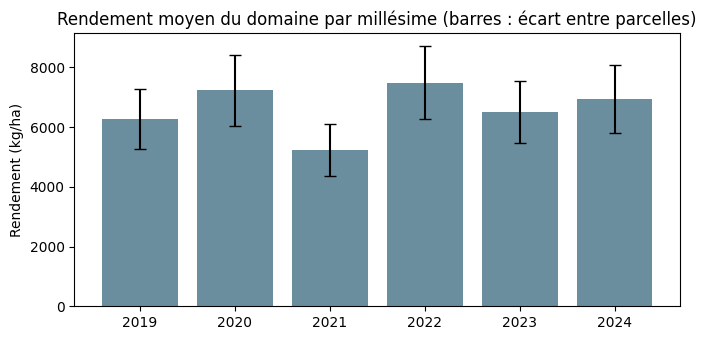

In [15]:
par_an = histo_ok.groupby("millesime")["rendement_kg_ha"].agg(["mean", "std"]).round(0)
print(par_an)
print("Écart-type entre parcelles (moyenne par parcelle) :", round(piv.mean(axis=1).std()))
print("Écart-type entre les moyennes annuelles du domaine :", round(piv.mean(axis=0).std()))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(par_an.index.astype(str), par_an["mean"], yerr=par_an["std"], capsize=4, color="#6b8e9e")
ax.set_ylabel("Rendement (kg/ha)")
ax.set_title("Rendement moyen du domaine par millésime (barres : écart entre parcelles)")
plt.tight_layout()
plt.show()

**Lecture.** Le niveau du domaine varie de 5 246 kg/ha (2021) à 7 495 kg/ha (2022), un effet du même ordre que l'écart entre parcelles. Aucune variable de la parcelle ne peut l'anticiper.

**Conséquence pour la mesure de l'erreur.** On sépare deux erreurs :

- l'**erreur sur le niveau du domaine** (la météo de l'année) : elle compte pour la trésorerie globale de la récolte ;
- l'**erreur entre parcelles**, après avoir retiré le niveau de l'année : c'est celle qui compte pour arbitrer le budget, car une bonne ou mauvaise année pour tout le domaine ne change pas le classement des parcelles.

On travaille donc sur le **rendement centré par année** (rendement moins la moyenne du domaine cette année-là).

## 5. Protocole de validation

On ne mélange pas les millésimes. Pour chaque année de test (2021 à 2024), on utilise uniquement les années précédentes : entraînement sur le passé, test sur l'année en question. Une validation croisée classique ferait voir le futur au modèle et donnerait une erreur trop optimiste.

Mesure principale : le **RMSE sans biais**, c'est-à-dire l'écart-type de l'erreur entre parcelles une fois l'effet d'année retiré. On le compare à l'écart-type du rendement entre parcelles pour l'année testée.

In [16]:
# Rendement centré par année : on retire le niveau moyen du domaine
piv_c = piv.sub(piv.mean(axis=0), axis=1)

resultats = []

def noter(annee, modele, y_vrai, y_pred):
    err = y_vrai - y_pred
    resultats.append({"année": annee, "modèle": modele, "RMSE sans biais": err.std(ddof=0)})

# Écart entre parcelles pour chaque année de test (point de comparaison de la Q4)
ecart_parcelles = {A: piv_c[A].std(ddof=0) for A in ANNEES_TEST}
print({A: round(v) for A, v in ecart_parcelles.items()})

{2021: 875, 2022: 1227, 2023: 1037, 2024: 1129}


## 6. Modèles de référence

Deux prévisions sans aucun modèle statistique :

- **année précédente** : on prédit le même écart à la moyenne que l'an dernier ;
- **moyenne passée** : on prédit la moyenne des écarts de toutes les années antérieures.

Le tableau « erreur brute » montre aussi ce que coûte l'effet d'année si on prédit directement le rendement en kg/ha.

In [17]:
for A in ANNEES_TEST:
    noter(A, "année précédente", piv_c[A], piv_c[A - 1])
    noter(A, "moyenne passée", piv_c[A], piv_c.loc[:, :A - 1].mean(axis=1))

# Erreur brute (en kg/ha) de la moyenne passée, avec l'effet d'année
brut = []
for A in ANNEES_TEST:
    err = piv[A] - piv.loc[:, :A - 1].mean(axis=1)
    brut.append({"année": A, "MAE": err.abs().mean(), "RMSE brut": np.sqrt((err ** 2).mean()),
                 "biais (effet d'année)": err.mean(), "RMSE sans biais": err.std(ddof=0)})
print(pd.DataFrame(brut).round(0).to_string(index=False))

 année    MAE  RMSE brut  biais (effet d'année)  RMSE sans biais
  2021 1518.0     1624.0                -1518.0            577.0
  2022 1243.0     1391.0                 1238.0            634.0
  2023  403.0      502.0                  -65.0            497.0
  2024  528.0      643.0                  390.0            511.0


**Lecture.** En 2021 et 2022, l'erreur brute est dominée par le biais (-1 518 et +1 238 kg/ha) : tout le domaine a fait une mauvaise puis une très bonne année. L'erreur entre parcelles, elle, reste stable.

## 7. Modèles avec les caractéristiques des parcelles

On teste si le sol, l'azote, la pente, etc. améliorent la prévision par rapport à l'historique seul. Les données sont organisées en une ligne par parcelle et par année : les caractéristiques de la parcelle plus le **niveau passé** (moyenne des écarts des années antérieures uniquement, donc sans fuite du futur). On exclut `rendement_kg_ha` et `classement_recolte` du fichier parcelles, qui contiennent l'année à prédire ou sont connus seulement après la récolte.

Traitement des valeurs manquantes : la pluviométrie est remplacée par la médiane (sans lien avec le rendement), l'exposition manquante devient une catégorie « inconnue ». Le texte est transformé en variables indicatrices.

In [18]:
X_stat = parc_ok.set_index("parcelle_id").drop(
    columns=["rendement_kg_ha", "classement_recolte", "rendement_nul_a_verifier"])
X_stat["exposition"] = X_stat["exposition"].fillna("inconnue")
X_stat["pluviometrie_mm"] = X_stat["pluviometrie_mm"].fillna(X_stat["pluviometrie_mm"].median())
X_stat = pd.get_dummies(X_stat, columns=["cepage", "type_sol", "exposition"], drop_first=True).astype(float)
X_stat = X_stat.loc[piv.index]

def construire(annee):
    """Variables et cible pour une année donnée, avec uniquement des informations antérieures."""
    X = X_stat.copy()
    X["niveau_passe"] = piv_c.loc[:, :annee - 1].mean(axis=1)
    return X, piv_c[annee]

cols_stat = list(X_stat.columns)
variantes = {
    "niveau passé seul": ["niveau_passe"],
    "caractéristiques seules": cols_stat,
    "caractéristiques + niveau passé": cols_stat + ["niveau_passe"],
}

def evaluer(nom, fabrique):
    for A in ANNEES_TEST:
        annees_train = range(2020, A)
        Xtr = pd.concat([construire(a)[0] for a in annees_train])
        ytr = pd.concat([construire(a)[1] for a in annees_train])
        Xte, yte = construire(A)
        for nom_var, cols in variantes.items():
            m = fabrique().fit(Xtr[cols], ytr)
            pred = pd.Series(m.predict(Xte[cols]), index=yte.index)
            noter(A, f"{nom} | {nom_var}", yte, pred)

evaluer("régression linéaire", LinearRegression)

## 8. KNN (k plus proches voisins)

Même protocole. Les variables sont standardisées, car les distances mélangent des unités très différentes (mètres, grammes, indicatrices).

In [19]:
for k in (5, 10, 20):
    evaluer(f"k-NN (k={k})",
            lambda k=k: make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k)))

## 9. Comparaison et choix du modèle

RMSE sans biais en kg/ha (plus c'est bas, mieux c'est). La dernière colonne donne la moyenne sur les quatre années testées.

In [20]:
res = pd.DataFrame(resultats)
tableau = res.pivot(index="modèle", columns="année", values="RMSE sans biais")
tableau["moyenne"] = tableau.mean(axis=1)
tableau = tableau.sort_values("moyenne")
print(tableau.round(0))

print("\nÉcart-type entre parcelles (à battre) :", {A: round(v) for A, v in ecart_parcelles.items()})

année                                                2021    2022   2023   2024  moyenne
modèle                                                                                  
moyenne passée                                      577.0   634.0  497.0  511.0    555.0
régression linéaire | niveau passé seul             552.0   683.0  492.0  523.0    562.0
k-NN (k=20) | niveau passé seul                     532.0   694.0  496.0  537.0    565.0
régression linéaire | caractéristiques + niveau...  586.0   669.0  531.0  540.0    581.0
k-NN (k=10) | niveau passé seul                     566.0   714.0  526.0  561.0    592.0
k-NN (k=5) | niveau passé seul                      651.0   741.0  530.0  574.0    624.0
k-NN (k=5) | caractéristiques + niveau passé        641.0   853.0  648.0  581.0    680.0
k-NN (k=5) | caractéristiques seules                703.0   901.0  652.0  560.0    704.0
année précédente                                    753.0   760.0  704.0  654.0    718.0
k-NN (k=10) | caracté

Part de l'écart entre parcelles expliquée (moyenne passée) :
année
2021    0.56
2022    0.73
2023    0.77
2024    0.80
dtype: float64


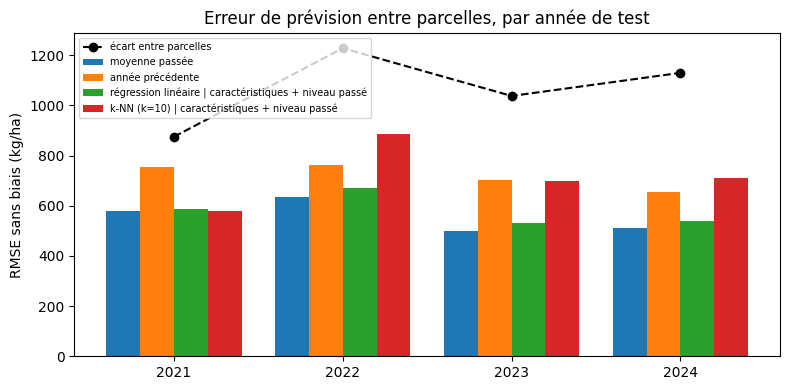

In [21]:
# Part de l'écart entre parcelles que la prévision permet de reproduire (moyenne passée)
mp = res[res["modèle"] == "moyenne passée"].set_index("année")["RMSE sans biais"]
part = 1 - (mp / pd.Series(ecart_parcelles)) ** 2
print("Part de l'écart entre parcelles expliquée (moyenne passée) :")
print(part.round(2))

# Graphique de comparaison
choix = ["moyenne passée", "année précédente",
         "régression linéaire | caractéristiques + niveau passé",
         "k-NN (k=10) | caractéristiques + niveau passé"]
fig, ax = plt.subplots(figsize=(8, 4))
largeur = 0.2
x = np.arange(len(ANNEES_TEST))
for i, nom in enumerate(choix):
    ax.bar(x + i * largeur, tableau.loc[nom, ANNEES_TEST], largeur, label=nom)
ax.plot(x + 1.5 * largeur, [ecart_parcelles[A] for A in ANNEES_TEST], "k--o", label="écart entre parcelles")
ax.set_xticks(x + 1.5 * largeur)
ax.set_xticklabels(ANNEES_TEST)
ax.set_ylabel("RMSE sans biais (kg/ha)")
ax.legend(fontsize=7)
ax.set_title("Erreur de prévision entre parcelles, par année de test")
plt.tight_layout()
plt.show()

**Lecture.**

- La **moyenne passée** fait aussi bien que tous les autres modèles, à quelques dizaines de kg/ha près, et bat nettement l'année précédente : le rendement d'une seule année contient trop de bruit.
- **Ajouter les caractéristiques des parcelles n'améliore pas la prévision** : l'historique d'une parcelle résume déjà l'effet de son sol, de son azote et de sa pente. Avec une vingtaine de colonnes et peu d'années d'entraînement, les modèles se dégradent même (surapprentissage, et pour k-NN, distances peu informatives en grande dimension).
- L'erreur entre parcelles reste nettement plus petite que l'écart entre deux parcelles : la prévision est utile pour arbitrer.
- Limite : le test de 2021 repose sur seulement deux années passées, il est plus fragile que les autres.
- Les caractéristiques servent donc à **expliquer** (Q1) et à **décider quoi changer** (Q8), pas à prédire mieux.

**Modèle retenu : la moyenne des écarts passés de chaque parcelle, ajoutée au niveau moyen du domaine.**

## 10. Prévision pour l'année à venir

Pour chaque parcelle : niveau moyen du domaine + écart moyen de la parcelle sur 2019-2024. L'incertitude sur le niveau du domaine (météo de l'année) est mesurée par l'écart-type des moyennes annuelles.

In [22]:
niveau = piv_c.mean(axis=1)          # écart moyen de chaque parcelle à la moyenne du domaine
base = piv.mean(axis=0).mean()       # niveau moyen du domaine
incertitude_niveau = piv.mean(axis=0).std()

prevision = pd.DataFrame({
    "rendement_prevu_kg_ha": (base + niveau).round(0),
    "ecart_a_la_moyenne": niveau.round(0),
})
prevision["classement"] = prevision["rendement_prevu_kg_ha"].rank(ascending=False, method="first").astype(int)
prevision = prevision.sort_values("classement")

print("Niveau moyen du domaine :", round(base), "kg/ha | incertitude sur le niveau annuel : ±", round(incertitude_niveau))
print("\nLes 10 meilleures parcelles :")
print(prevision.head(10))
print("\nLes 10 moins bonnes :")
print(prevision.tail(10))

prevision.to_csv("../data/processed/q3_previsions.csv")

Niveau moyen du domaine : 6619 kg/ha | incertitude sur le niveau annuel : ± 809

Les 10 meilleures parcelles :
             rendement_prevu_kg_ha  ecart_a_la_moyenne  classement
parcelle_id                                                       
P90                         9375.0              2756.0           1
P155                        9162.0              2543.0           2
P229                        9025.0              2406.0           3
P29                         8898.0              2279.0           4
P204                        8778.0              2159.0           5
P222                        8653.0              2034.0           6
P221                        8633.0              2014.0           7
P124                        8497.0              1878.0           8
P206                        8456.0              1837.0           9
P191                        8382.0              1763.0          10

Les 10 moins bonnes :
             rendement_prevu_kg_ha  ecart_a_la_moyenne  classe

## 11. Réponses

> À relire une fois les sorties vérifiées : les chiffres ci-dessous viennent de l'exécution du notebook.

**Q3. Que va donner chaque parcelle cette année ?**
Le fichier `q3_previsions.csv` donne, pour 214 parcelles, un rendement prévu et un classement. La prévision est le niveau moyen du domaine (environ 6 620 kg/ha) corrigé de l'écart habituel de chaque parcelle. Elle couvre 214 parcelles sur 220 : trois ont des données d'historique en conflit, trois affichent un rendement nul sur six ans, et ces six parcelles demandent une vérification sur le terrain avant toute décision.

**Q4. Sur quoi repose-t-elle, et de combien se trompe-t-elle ?**
Elle repose uniquement sur l'historique de chaque parcelle : une parcelle qui a bien donné une année donne bien les autres (corrélation de 0,9 entre millésimes). Il y a deux erreurs à distinguer. Entre parcelles, la prévision se trompe d'environ 500 à 630 kg/ha selon l'année, contre un écart-type de 875 à 1 230 kg/ha entre parcelles selon l’année : elle est assez précise pour classer les parcelles et répartir le budget. Sur le niveau global du domaine, l'incertitude est d'environ 800 kg/ha, car la météo de l'année touche toutes les parcelles à la fois (5 246 kg/ha en 2021 contre 7 495 kg/ha en 2022) et aucune donnée de parcelle ne permet de l'anticiper. Cette seconde incertitude compte pour la trésorerie de la récolte, pas pour l'arbitrage entre parcelles.

**Pourquoi ce modèle ?** Les modèles plus complexes testés (régression linéaire avec les caractéristiques, k plus proches voisins) ne font pas mieux que la moyenne passée, et ajoutent des variables sans gain. À performance égale, on retient le plus simple et le plus facile à expliquer.

**Limites.** Six années d'historique seulement, un test de 2021 fragile (deux années passées), et un modèle qui prédit un niveau, pas l'effet d'un changement de dose d'azote : pour le gain de rendement attendu du budget, la corrélation observée ne prouve pas une causalité.